# 3. Modelo de von Bertalanffy

> **Os dados deste projeto são SIMULADOS** (ver notebook 01). Não são registos de nenhuma exploração.

A curva de von Bertalanffy é o modelo de crescimento mais usado em biologia pesqueira. Neste notebook:
1. ajustamos a curva (em peso) às biometrias de cada espécie, com `scipy.optimize.curve_fit`;
2. avaliamos o ajuste (R² e resíduos);
3. mostramos um problema importante: **com dados de aquacultura não é possível estimar o peso assintótico W∞**, e vemos o que isso significa com uma análise de sensibilidade.

As funções estão em `src/von_bertalanffy.py`.

## 3.1 A equação

$$W(t) = W_\infty \left(1 - e^{-k\,(t - t_0)}\right)^3$$

| Parâmetro | Significado | Unidade |
|---|---|---|
| $W_\infty$ | Peso assintótico: o peso máximo que o peixe atingiria se vivesse indefinidamente | g |
| $k$ | Coeficiente de crescimento: a rapidez com que o peixe se aproxima de $W_\infty$ | dia⁻¹ (multiplicado por 365 dá ano⁻¹) |
| $t_0$ | Idade teórica em que o peso seria zero; é um parâmetro de ajuste, sem significado biológico direto | dias |

O expoente 3 vem de o peso ser aproximadamente proporcional ao **comprimento ao cubo**. A curva tem forma de S: começa devagar, acelera e depois abranda até "achatar" em $W_\infty$.

**Diferença em relação ao modelo da simulação:** os dados foram gerados com o modelo TGC (notebook 01), em que o peixe cresce com a temperatura acumulada acima de 12 °C e que **não tem assíntota** (o peixe nunca para de crescer). A curva de von Bertalanffy não usa a temperatura e assume que existe um peso máximo. Vamos ver as consequências.

In [1]:
import sys
sys.path.append("..")   # para o Python encontrar a pasta src/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.dados import ler_registos
from src.von_bertalanffy import vb_peso, ajustar_vb

sns.set_theme(style="whitegrid", context="notebook")
CORES = {"dourada": "#c9971c", "robalo": "#3f6ea6"}
NOMES = {"dourada": "Dourada (Sparus aurata)", "robalo": "Robalo (Dicentrarchus labrax)"}
ESPECIES = ["dourada", "robalo"]

registos = ler_registos("../data/raw/registos_simulados.csv")

## 3.2 Ajuste livre (W∞, k e t0)

O `curve_fit` procura os valores dos três parâmetros que minimizam a soma dos quadrados dos resíduos (diferença entre o peso observado e o previsto). Os **intervalos de confiança a 95 %** são calculados a partir dos erros-padrão das estimativas: estimativa ± t × erro-padrão.

Limitamos $W_\infty$ a um máximo de 100 kg para o algoritmo não "fugir" para o infinito.

In [2]:
ajustes_livres = {}
linhas = []
for especie in ESPECIES:
    reg = registos[registos["especie"] == especie]
    aj = ajustar_vb(reg["dia"], reg["peso_medio_g"])
    ajustes_livres[especie] = aj
    for nome, unidade in [("w_inf", "g"), ("k", "dia⁻¹"), ("t0", "dias")]:
        baixo, alto = aj["ic95"][nome]
        linhas.append({"espécie": especie, "parâmetro": f"{nome} ({unidade})",
                       "estimativa": aj["parametros"][nome],
                       "IC 95 % (mín.)": baixo, "IC 95 % (máx.)": alto})
    print(f"{especie}: R² = {aj['r2']:.4f}")

pd.DataFrame(linhas).set_index(["espécie", "parâmetro"]).style.format("{:.4g}")

dourada: R² = 0.9917
robalo: R² = 0.9853


**O ajuste parece muito bom (R² ≈ 0,99), mas os parâmetros não fazem sentido:**
- Nas duas espécies, $W_\infty$ vai até ao **limite de 100 kg** que impusemos: o algoritmo "quer" um peso máximo infinito. Os intervalos de confiança de $W_\infty$ incluem **valores negativos**: os dados são compatíveis com quase qualquer peso assintótico.

**Porquê?** Para estimar uma assíntota é preciso ver a curva a **achatar**. Os nossos dados vão de 3 g a cerca de 450–550 g, uma fração muito pequena do tamanho máximo destas espécies, e nesta fase o crescimento ainda está a **acelerar** (em gramas por dia). Há muitas combinações de $W_\infty$ e $k$ que desenham praticamente a mesma curva nesta zona: um $W_\infty$ maior compensa-se com um $k$ menor. Em estatística diz-se que $W_\infty$ **não é identificável** com estes dados.

Isto não é um defeito dos dados simulados: acontece também com dados reais de aquacultura, porque os peixes são vendidos muito antes de se aproximarem do tamanho máximo. Mais ainda, nos nossos dados não existe assíntota nenhuma, porque o modelo que os gerou não tem.

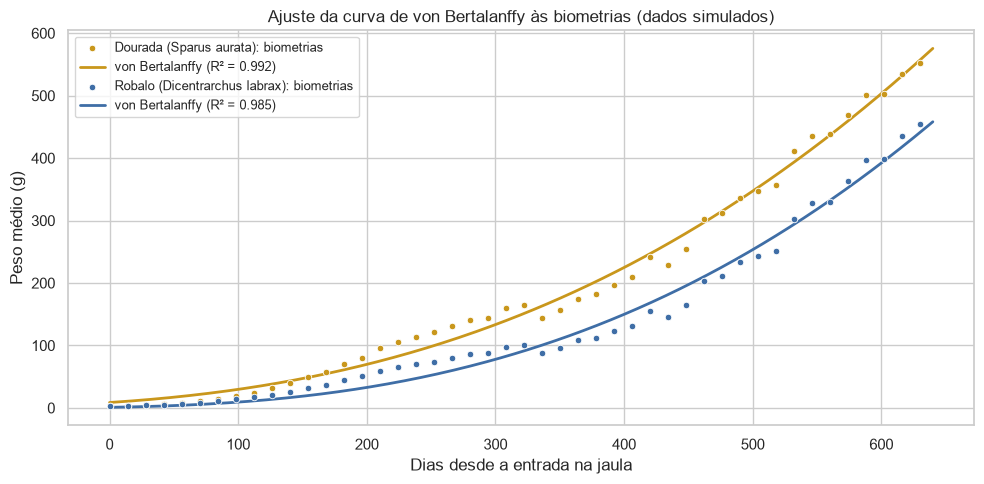

In [3]:
fig, ax = plt.subplots(figsize=(10, 5))
dias_curva = np.linspace(0, 640, 300)
for especie in ESPECIES:
    reg = registos[registos["especie"] == especie]
    aj = ajustes_livres[especie]
    ax.scatter(reg["dia"], reg["peso_medio_g"], color=CORES[especie], s=22, edgecolor="white",
               linewidth=0.6, zorder=3, label=f"{NOMES[especie]}: biometrias")
    ax.plot(dias_curva, vb_peso(dias_curva, **aj["curva"]), color=CORES[especie], linewidth=2,
            label=f"von Bertalanffy (R² = {aj['r2']:.3f})")
ax.set_title("Ajuste da curva de von Bertalanffy às biometrias (dados simulados)")
ax.set_xlabel("Dias desde a entrada na jaula")
ax.set_ylabel("Peso médio (g)")
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig("../figures/03_ajuste_vb.png", dpi=150)
plt.show()

## 3.3 Resíduos

Um R² alto não chega para dizer que o modelo é adequado. Os **resíduos** (observado − previsto) devem estar espalhados ao acaso à volta de zero, sem padrão.

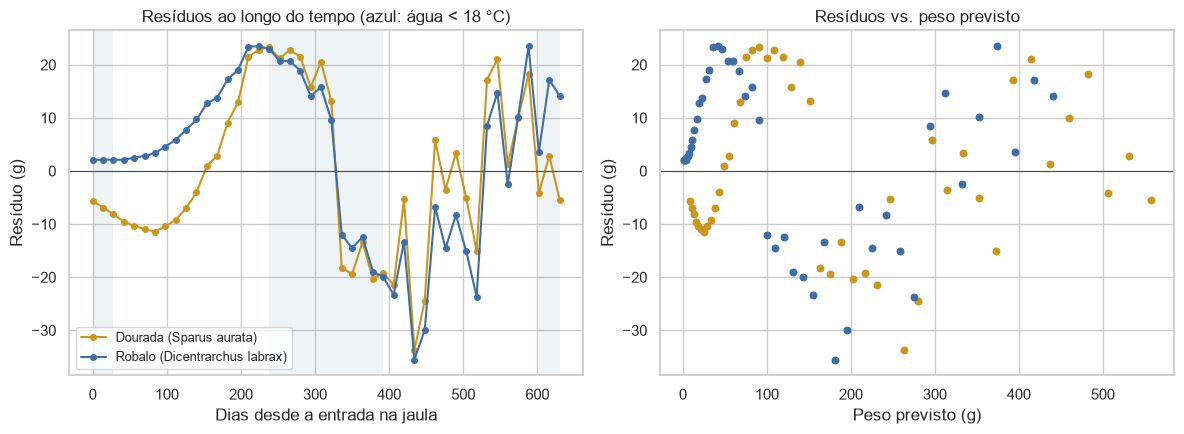

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
for especie in ESPECIES:
    reg = registos[registos["especie"] == especie]
    aj = ajustes_livres[especie]
    ax1.plot(reg["dia"], aj["residuos"], "o-", color=CORES[especie], markersize=4, label=NOMES[especie])
    ax2.scatter(aj["previsto"], aj["residuos"], color=CORES[especie], s=22, label=NOMES[especie])

# Sombrear os meses frios (temperatura do período abaixo de 18 °C)
reg = registos[registos["especie"] == "dourada"]
for dia, temp in zip(reg["dia"], reg["temperatura_c"]):
    if temp < 18:
        ax1.axvspan(max(dia - 14, 0), dia, color="#2a6f97", alpha=0.08, linewidth=0)

for ax in (ax1, ax2):
    ax.axhline(0, color="0.3", linewidth=0.8)
    ax.set_ylabel("Resíduo (g)")
ax1.set_title("Resíduos ao longo do tempo (azul: água < 18 °C)")
ax1.set_xlabel("Dias desde a entrada na jaula")
ax1.legend(fontsize=9)
ax2.set_title("Resíduos vs. peso previsto")
ax2.set_xlabel("Peso previsto (g)")
plt.tight_layout()
plt.savefig("../figures/03_residuos.png", dpi=150)
plt.show()

Os resíduos **não** são aleatórios:

1. **Padrão sazonal (esquerda):** há longas sequências de resíduos com o mesmo sinal, iguais nas duas espécies. A curva sobrestima o peso dos juvenis nos primeiros 150 dias na dourada (resíduos negativos), subestima-o no primeiro verão e outono (positivos, até ≈ +23 g) e volta a sobrestimá-lo a seguir ao primeiro inverno (dias ≈ 330–450), quando o crescimento real parou quase por completo (abaixo de 12 °C de temperatura efetiva a dourada não cresce). A curva de von Bertalanffy é "lisa" e não sabe que o crescimento para no inverno e acelera no verão. Como os resíduos seguidos não são independentes, os **intervalos de confiança acima são otimistas** (demasiado estreitos).
2. **Os resíduos variam mais nos peixes grandes (direita):** a partir de ≈ 250 g os erros saltam de um lado para o outro, sobretudo por causa do **erro de amostragem**, que cresce com o tamanho dos peixes (notebook 02).

Uma melhoria conhecida é a **curva de von Bertalanffy sazonal** (Somers, 1988), que acrescenta uma oscilação anual ao crescimento. Não a usamos aqui para manter o modelo simples; nos cenários (notebook 04) usamos diretamente o modelo com temperatura.

## 3.4 Análise de sensibilidade: W∞ fixo

Uma solução comum quando $W_\infty$ não é identificável é **fixá-lo** num valor conhecido e estimar apenas $k$ e $t_0$. O problema é que **não encontrámos um $W_\infty$ publicado para peixes de cultivo**. Os valores disponíveis vêm de populações selvagens e variam muito:

- **Dourada:** $W_\infty$ = 12 819 g no Adriático oriental (Kraljević, Dulčić & Tudor, 1998, *Periodicum Biologorum* 100: 87–91), com peixes selvagens de 40 a 5 900 g; é uma extrapolação para lá do maior peixe observado.
- **Robalo:** não encontrámos $W_\infty$ publicado; os estudos em populações selvagens (ex.: El-Desoki et al., 2021, lagoa de Bardawil, Egito) só reportam comprimento assintótico.

Em vez de escolhermos um valor sem justificação, fazemos uma **análise de sensibilidade**: fixamos $W_\infty$ em **2, 5 e 13 kg** (este último próximo do valor de Kraljević et al., 1998) e vemos o que muda.

In [5]:
W_INF_TESTE = [2000, 5000, 13000]   # g

ajustes_fixos = {}
linhas = []
for especie in ESPECIES:
    reg = registos[registos["especie"] == especie]
    for w_inf in W_INF_TESTE:
        aj = ajustar_vb(reg["dia"], reg["peso_medio_g"], w_inf_fixo=w_inf)
        ajustes_fixos[(especie, w_inf)] = aj
        k, t0 = aj["parametros"]["k"], aj["parametros"]["t0"]
        k_min, k_max = aj["ic95"]["k"]
        linhas.append({
            "espécie": especie,
            "W∞ fixo (kg)": w_inf / 1000,
            "k (ano⁻¹)": round(k * 365, 3),
            "k IC 95 % (ano⁻¹)": f"{k_min * 365:.3f} – {k_max * 365:.3f}",
            "t0 (dias)": round(t0, 1),
            "R²": round(aj["r2"], 4),
            "peso previsto ao dia 1000 (g)": round(vb_peso(1000, **aj["curva"])),
        })
sensibilidade = pd.DataFrame(linhas).set_index(["espécie", "W∞ fixo (kg)"])
sensibilidade

k (ano⁻¹) k IC 95 % (ano⁻¹)  t0 (dias)      R²  \
espécie W∞ fixo (kg)                                                   
dourada 2.0               0.549     0.520 – 0.578      -49.9  0.9842   
        5.0               0.321     0.308 – 0.335     -105.5  0.9892   
        13.0              0.202     0.194 – 0.210     -143.9  0.9908   
robalo  2.0               0.517     0.477 – 0.556       -0.0  0.9700   
        5.0               0.327     0.307 – 0.348      -18.7  0.9785   
        13.0              0.209     0.197 – 0.221      -48.9  0.9821   

                      peso previsto ao dia 1000 (g)  
espécie W∞ fixo (kg)                                 
dourada 2.0                                    1001  
        5.0                                    1204  
        13.0                                   1341  
robalo  2.0                                     868  
        5.0                                    1075  
        13.0                                   1199

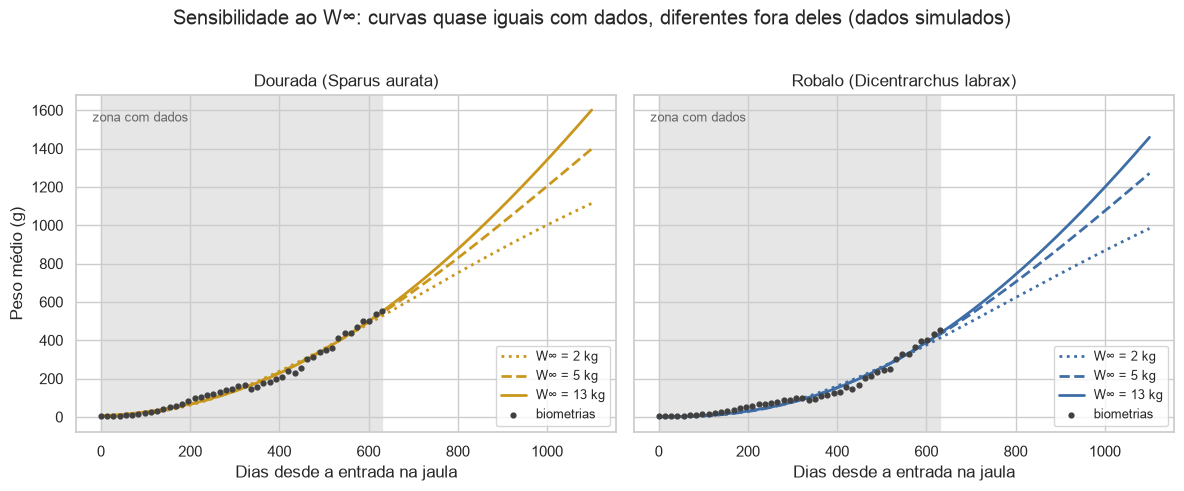

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
dias_curva = np.linspace(0, 1100, 400)
estilos = {2000: ":", 5000: "--", 13000: "-"}
for ax, especie in zip(axes, ESPECIES):
    reg = registos[registos["especie"] == especie]
    ax.axvspan(0, reg["dia"].max(), color="0.9", zorder=0)
    ax.text(0.03, 0.95, "zona com dados", transform=ax.transAxes, fontsize=9, color="0.4", va="top")
    for w_inf in W_INF_TESTE:
        aj = ajustes_fixos[(especie, w_inf)]
        ax.plot(dias_curva, vb_peso(dias_curva, **aj["curva"]), color=CORES[especie],
                linestyle=estilos[w_inf], linewidth=2, label=f"W∞ = {w_inf / 1000:g} kg")
    ax.scatter(reg["dia"], reg["peso_medio_g"], color="0.25", s=12, zorder=3, label="biometrias")
    ax.set_title(NOMES[especie])
    ax.set_xlabel("Dias desde a entrada na jaula")
    ax.legend(fontsize=9, loc="lower right")
axes[0].set_ylabel("Peso médio (g)")
fig.suptitle("Sensibilidade ao W∞: curvas quase iguais com dados, diferentes fora deles (dados simulados)", y=1.02)
plt.tight_layout()
plt.savefig("../figures/03_sensibilidade_winf.png", dpi=150, bbox_inches="tight")
plt.show()

**Leitura:**
- **Dentro da zona com dados** as três curvas são quase iguais e todas têm R² entre 0,97 e 0,99. Os dados não conseguem distinguir entre elas.
- **O $k$ muda cerca de 2,5 vezes** consoante o $W_\infty$ escolhido (dourada: ≈ 0,55 ano⁻¹ com 2 kg; ≈ 0,20 ano⁻¹ com 13 kg). Por isso **$k$ não deve ser interpretado sozinho**: só faz sentido junto com o $W_\infty$ com que foi estimado. Comparar valores de $k$ entre estudos com $W_\infty$ diferentes é um erro frequente.
- Os intervalos de confiança de $k$ são estreitos *para cada* $W_\infty$, mas a incerteza verdadeira é muito maior, porque não sabemos qual $W_\infty$ é o certo.
- No robalo com $W_\infty$ = 2 kg, $t_0$ fica **no limite de 0 dias** que impusemos (com $t_0 > 0$ a curva daria pesos negativos no início do ciclo). É mais um sinal de que a curva, com esse valor de $W_\infty$, não se adapta bem à forma dos dados; nesse caso os intervalos de confiança são pouco fiáveis.
- **Fora da zona com dados** as curvas separam-se: ao dia 1000 a previsão da dourada varia entre ≈ 1 000 e ≈ 1 340 g, e a do robalo entre ≈ 870 e ≈ 1 200 g, consoante o $W_\infty$. **Extrapolar** uma curva de von Bertalanffy ajustada a dados de engorda é arriscado.

## 3.5 Conclusões

1. A curva de von Bertalanffy **descreve bem** o crescimento observado (R² ≥ 0,97 em todos os casos), por isso é útil para **resumir** e **interpolar** os dados de um ciclo de engorda.
2. Com dados de aquacultura (só a fase inicial do crescimento), **$W_\infty$ não é identificável**: o ajuste livre dá valores absurdos e intervalos de confiança enormes.
3. Fixando $W_\infty$, as estimativas de $k$ dependem muito do valor escolhido e os parâmetros perdem significado biológico. **Não encontrámos um $W_\infty$ publicado para peixes de cultivo**; os valores de populações selvagens (Kraljević et al., 1998) servem só como referência.
4. Os resíduos mostram um **padrão sazonal**, que a curva não capta por não incluir a temperatura. Para prever o efeito da temperatura (notebook 04) usamos o modelo TGC do notebook 01.

**Limitações:** dados simulados; ajuste por mínimos quadrados não ponderados e com resíduos autocorrelacionados (intervalos de confiança otimistas).